In [24]:
import pandas as pd
from Bio import SeqIO
import matplotlib.pyplot as plt

In [32]:
padi_data = pd.read_excel('Morffy_supp_table_3.xlsx')
padi_data

,ARF Clade,Clade A ARF Subclade,Species,Model,Start Position,Fragment Sequence,ScaleScore
0,Clade C,NaN,Amborella trichopododa,evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_27.mo...,1,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSN,0.132163
1,Clade C,NaN,Amborella trichopododa,evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_27.mo...,11,TAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFASLSS,0.698559
2,Clade C,NaN,Amborella trichopododa,evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_27.mo...,21,RLSPHLDFPIDSTFHPLSSNIDPTFASLSSNLNPTPLTSS,1.002289
3,Clade C,NaN,Amborella trichopododa,evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_27.mo...,31,DSTFHPLSSNIDPTFASLSSNLNPTPLTSSMPRPTNPFQG,0.216912
4,Clade C,NaN,Amborella trichopododa,evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_27.mo...,41,IDPTFASLSSNLNPTPLTSSMPRPTNPFQGLPDYHVPAGI,-0.182901
...,...,...,...,...,...,...,...
9538,NaN,NaN,Arabidopsis thaliana,ARF7_AD2_DEtoA,1,GANNRQQNFLAPTFGLAGASRNSLLGGANVANGFVPATLL,-0.119703
9539,NaN,NaN,Arabidopsis thaliana,ARF19_AD1_minusswapplus,1,PPFFDPEYPDQPGMPRRKLRMKNAFEDAMPWMGKRFGMER,-0.348388
9540,NaN,NaN,Arabidopsis thaliana,ARF19_AD2_minusswapplus,1,SQLQQQSMLPTGAEMTHQNINSMGNEGLSQMTSFAQKMQF,-0.758803
9541,NaN,NaN,Arabidopsis thaliana,ARF7_AD1_minusswapplus,1,PPFFDPDFSGQPGMPRRKTRMKSALEDAMPWLRNSLKMER,-0.394609


In [ ]:
seq_ls = []
name_ls = []
weak_ad_ls = []
medium_ad_ls = []
strong_ad_ls = []

for name, df in padi_data.groupby('Model'): 
    sorted_df = df.sort_values('Start Position')
    seq = ""
    for i in sorted_df.index: 
        start = sorted_df.loc[i, 'Start Position'] - 1
        if start > len(seq):
            print("GAP before", sorted_df.loc[i, 'Start Position'])
        if not seq[start: ] in sorted_df.loc[i, 'Fragment Sequence']: 
            print("ERROR")
        seq = seq[:start] + sorted_df.loc[i, 'Fragment Sequence']

    # Look for and merge "weak" ADs (greater than 1 score)
    weak_ads = []
    ad_seq = ""

    for i in sorted_df.index: 
        score = sorted_df.loc[i, 'ScaleScore']
        if score > 1: 
            # If there is no current AD
            if len(ad_seq) == 0: 
                ad_seq += sorted_df.loc[i, 'Fragment Sequence']

            # If the AD we found overlaps with the current AD
            elif sorted_df.loc[i, 'Fragment Sequence'][:10] in ad_seq:
                start = ad_seq.find(sorted_df.loc[i, 'Fragment Sequence'][:10])
                ad_seq = ad_seq[:start] + sorted_df.loc[i, 'Fragment Sequence']
            
            # If we have found a new AD that doesn't overlap
            else: 
                weak_ads.append(ad_seq)
                ad_seq = sorted_df.loc[i, 'Fragment Sequence']

    if len(ad_seq) > 0:
        weak_ads.append(ad_seq)

    
    # Look for and merge "medium" ADs (greater than 2 score)
    medium_ads = []
    ad_seq = ""

    for i in sorted_df.index: 
        score = sorted_df.loc[i, 'ScaleScore']
        if score > 2: 
            # If there is no current AD
            if len(ad_seq) == 0: 
                ad_seq += sorted_df.loc[i, 'Fragment Sequence']

            # If the AD we found overlaps with the current AD
            elif sorted_df.loc[i, 'Fragment Sequence'][:10] in ad_seq:
                start = ad_seq.find(sorted_df.loc[i, 'Fragment Sequence'][:10])
                ad_seq = ad_seq[:start] + sorted_df.loc[i, 'Fragment Sequence']
            
            # If we have found a new AD that doesn't overlap
            else: 
                medium_ads.append(ad_seq)
                ad_seq = sorted_df.loc[i, 'Fragment Sequence']

    if len(ad_seq) > 0:
        medium_ads.append(ad_seq)

    # Look for and merge "strong" ADs (greater than 4 score)
    strong_ads = []
    ad_seq = ""

    for i in sorted_df.index: 
        score = sorted_df.loc[i, 'ScaleScore']
        if score > 3: 
            # If there is no current AD
            if len(ad_seq) == 0: 
                ad_seq += sorted_df.loc[i, 'Fragment Sequence']

            # If the AD we found overlaps with the current AD
            elif sorted_df.loc[i, 'Fragment Sequence'][:10] in ad_seq:
                start = ad_seq.find(sorted_df.loc[i, 'Fragment Sequence'][:10])
                ad_seq = ad_seq[:start] + sorted_df.loc[i, 'Fragment Sequence']
            
            # If we have found a new AD that doesn't overlap
            else: 
                strong_ads.append(ad_seq)
                ad_seq = sorted_df.loc[i, 'Fragment Sequence']

    if len(ad_seq) > 0:
        strong_ads.append(ad_seq)
    
    seq_ls.append(seq)
    name_ls.append(name)
    weak_ad_ls.append(weak_ads)
    medium_ad_ls.append(medium_ads)
    strong_ad_ls.append(strong_ads)

ad_df = pd.DataFrame({'sequence' : seq_ls, 'name' : name_ls, 'weak_ads' : weak_ad_ls, 'medium_ads' : medium_ad_ls, 'strong_ads' : strong_ad_ls})

In [61]:
ad_df.to_csv("Arf_seqs_w_ADs.csv")

In [62]:
ad_df

,sequence,name,weak_ads,medium_ads,strong_ads
0,PVITPFYICPPPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDF...,AL1G31800|AL1G31800.t1,[PPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKDAQSSM...,[PPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKDAQSSM...,"[PPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKD, QSF..."
1,TPESLFIFPSLTSGLKRQLHPSYFAGETEWGSLIKRPLIRVPDSAN...,AL1G32580|AL1G32580.t1,[KVNQLLQKPGASSPVQADPCLDISQQIYPPQSDPINGFSFLETDE...,[ASSPVQADPCLDISQQIYPPQSDPINGFSFLETDELTSQVSSFQS...,[ASSPVQADPCLDISQQIYPPQSDPINGFSFLETDELTSQVSSFQS...
2,PLTTFPMYPSPFPLRLKRPWPPGLPSFHGLKEDDMGMSMSSPLMWD...,AL1G44270|AL1G44270.t1,"[PPGLPSFHGLKEDDMGMSMSSPLMWDRGLQSLNFQGMGGN, GLL...",[PPGLPSFHGLKEDDMGMSMSSPLMWDRGLQSLNFQGMGGN],[PPGLPSFHGLKEDDMGMSMSSPLMWDRGLQSLNFQGMGGN]
3,HLIPSSSISQPTVLQKKRARQCNEIGSTSSNLLTGQEIGQSSLSSP...,AL1G48670|AL1G48670.t2,[NLLTGQEIGQSSLSSPKSVPEFSCRDAVEDSKFPSDWLMSDLVPA...,[],[]
4,HSTPSSNVLPSSMLKNKRSREFNEIGSSSSHLLPPILTQGQEIGQP...,AL1G48960|AL1G48960.t1,[QEIGQPSMTSPMNVPLSYRDAIEDDSTPSRLLMSYSVQTM],[QEIGQPSMTSPMNVPLSYRDAIEDDSTPSRLLMSYSVQTM],[]
...,...,...,...,...,...
363,PSAAPTAINPPPIPRAKRPRTNVPSPSDVSHLSREGLPRGMTEHSQ...,evm_27.TU.AmTr_v1.0_scaffold00057.126|evm_27.m...,[],[],[]
364,PLTTFPMYPSPFPLRLKRPWPPGLPSLHGNKDDDLGMSAPLMWLRD...,evm_27.TU.AmTr_v1.0_scaffold00092.36|evm_27.mo...,"[PPGLPSLHGNKDDDLGMSAPLMWLRDGADRNMQSLNFQGL, SHQ...",[SHQLQHQHSFNDQQQQNSQHNSQQNQQQLPDQQQTQQQQF],[SHQLQHQHSFNDQQQQNSQHNSQQNQQQLPDQQQTQQQQF]
365,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFA...,evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_27.mo...,[RLSPHLDFPIDSTFHPLSSNIDPTFASLSSNLNPTPLTSS],[],[]
366,VVSNIPTLQISPFSLPKKKHRISHPDFSSLDGTHCSLVGPTPTLPP...,evm_27.TU.AmTr_v1.0_scaffold00155.56|evm_27.mo...,[],[],[]


In [58]:
with open('arf_seqs.fasta', 'w+') as f:
    for i in ad_df.index:
        f.write(">" + ad_df.loc[i, 'name'] + "\n")
        f.write(ad_df.loc[i, 'sequence'] + '\n')

In [59]:
with open('arf_seqs.tsv', 'w+') as f:
    for i in ad_df.index:
        f.write(ad_df.loc[i, 'name'] + " ")
        f.write(ad_df.loc[i, 'sequence'] + '\n')

# Exploring an example sequence

In [52]:
len('QSFGIPSIPFKSGCSNEVGGINDSGIMNGGGLWPNQTQRM')

40

In [53]:
'PVITPFYICPPPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKDAQSSMFPGLSLVQWMSMQQNNPLSGSATPQLPSALSSYNLPNNFASNDPSKLLNFQSPNLSSANSQFNKSNTVNHISQQMQAQPAMVKSLQQQQQQQQQQLQQQQQQQLQISHQQLQQQGNYSNGASAVANQVSCQNPNQPTGFSQSQLQQQSMLPSGAKMIHQNINSVGNKGSSQMTSFVQEMQFQQQLELHNSSQLLRNQQEQSSLHSSQQNLSQNPQQLQMQQQSSKPSPSQQLQLQLLQKLQQQQQQQSVPPVSSSLQPQLSVLQQTQSHQLQQLLSSQNQQPLAHGNNSFSASTFMQPPQIQVSHQQQEQMNNKNLVAAGQSHSGHTDGEAPSCSTSPSANHTGHDNVSPTNFLSRNQQQGQAASVSASDSVFDRASNPVQEHYTKTESRFNQGMVNLKSGGEQFRFKGAVTDQIDVSTAGATYCPDVVGPAQQQQTFPLPSFGFDGDCQSHHPRNNLAFPGNLEAVTSDVLYSQKDFQNLVPNYGNAPRDIETELSSAAISSQSFGIPSIPFKSGCSNEVGGINDSGIMNGGGLWPNQTQRM'.find('QSFGIPSIPFKSGCSNEVGGINDSGIMNGGGLWPNQTQRM')

558

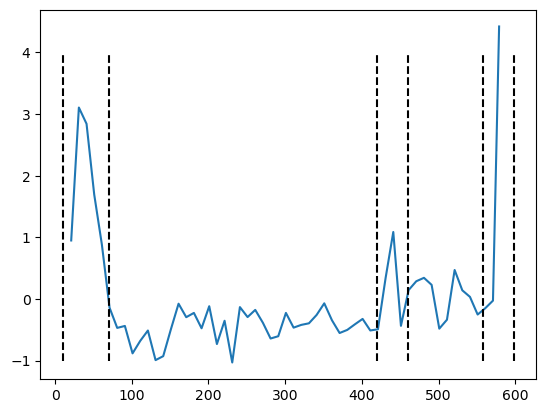

In [54]:
plt.plot(padi_data[padi_data['Model'] == 'AL1G31800|AL1G31800.t1']['Start Position'].values + 20, 
         padi_data[padi_data['Model'] == 'AL1G31800|AL1G31800.t1']['ScaleScore'].values)

plt.vlines(10, -1, 4, color='black', linestyles='--')
plt.vlines(10 + 60, -1, 4, color='black', linestyles='--')

plt.vlines(420, -1, 4, color='black', linestyles='--')
plt.vlines(420 + 40, -1, 4, color='black', linestyles='--')

plt.vlines(558, -1, 4, color='black', linestyles='--')
plt.vlines(558 + 40, -1, 4, color='black', linestyles='--')